<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/ML%20for%2050_Startups.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/50_Startups.csv')

In [3]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [5]:
df.isna().sum()

,0
R&D Spend,0
Administration,0
Marketing Spend,0
State,0
Profit,0


In [6]:
# Convert the 'State' column (assuming it contains 'New York')
# to numerical data using one-hot encoding or label encoding.
# Here's an example using one-hot encoding with pandas get_dummies:
df = pd.get_dummies(df, columns=['State'], prefix=['State']) # Assuming 'State' is the column name
df.corr()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
R&D Spend,1.000000,0.241955,0.724248,0.972900,-0.143165,0.105711,0.039068
Administration,0.241955,1.000000,-0.032154,0.200717,-0.015478,0.010493,0.005145
Marketing Spend,0.724248,-0.032154,1.000000,0.747766,-0.168875,0.205685,-0.033670
Profit,0.972900,0.200717,0.747766,1.000000,-0.145837,0.116244,0.031368
State_California,-0.143165,-0.015478,-0.168875,-0.145837,1.000000,-0.492366,-0.515152
State_Florida,0.105711,0.010493,0.205685,0.116244,-0.492366,1.000000,-0.492366
State_New York,0.039068,0.005145,-0.033670,0.031368,-0.515152,-0.492366,1.000000


<Axes: >

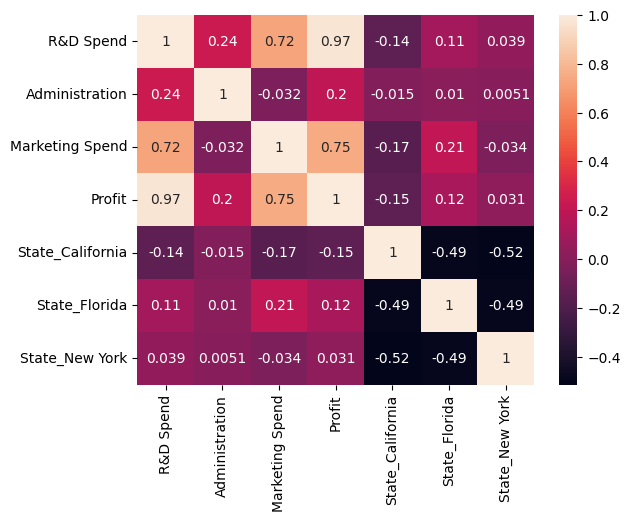

In [7]:
# coor for color
sns.heatmap(df.corr(), annot=True)
# annot= true لعمل الارقام فوق الرسمه الحراريه

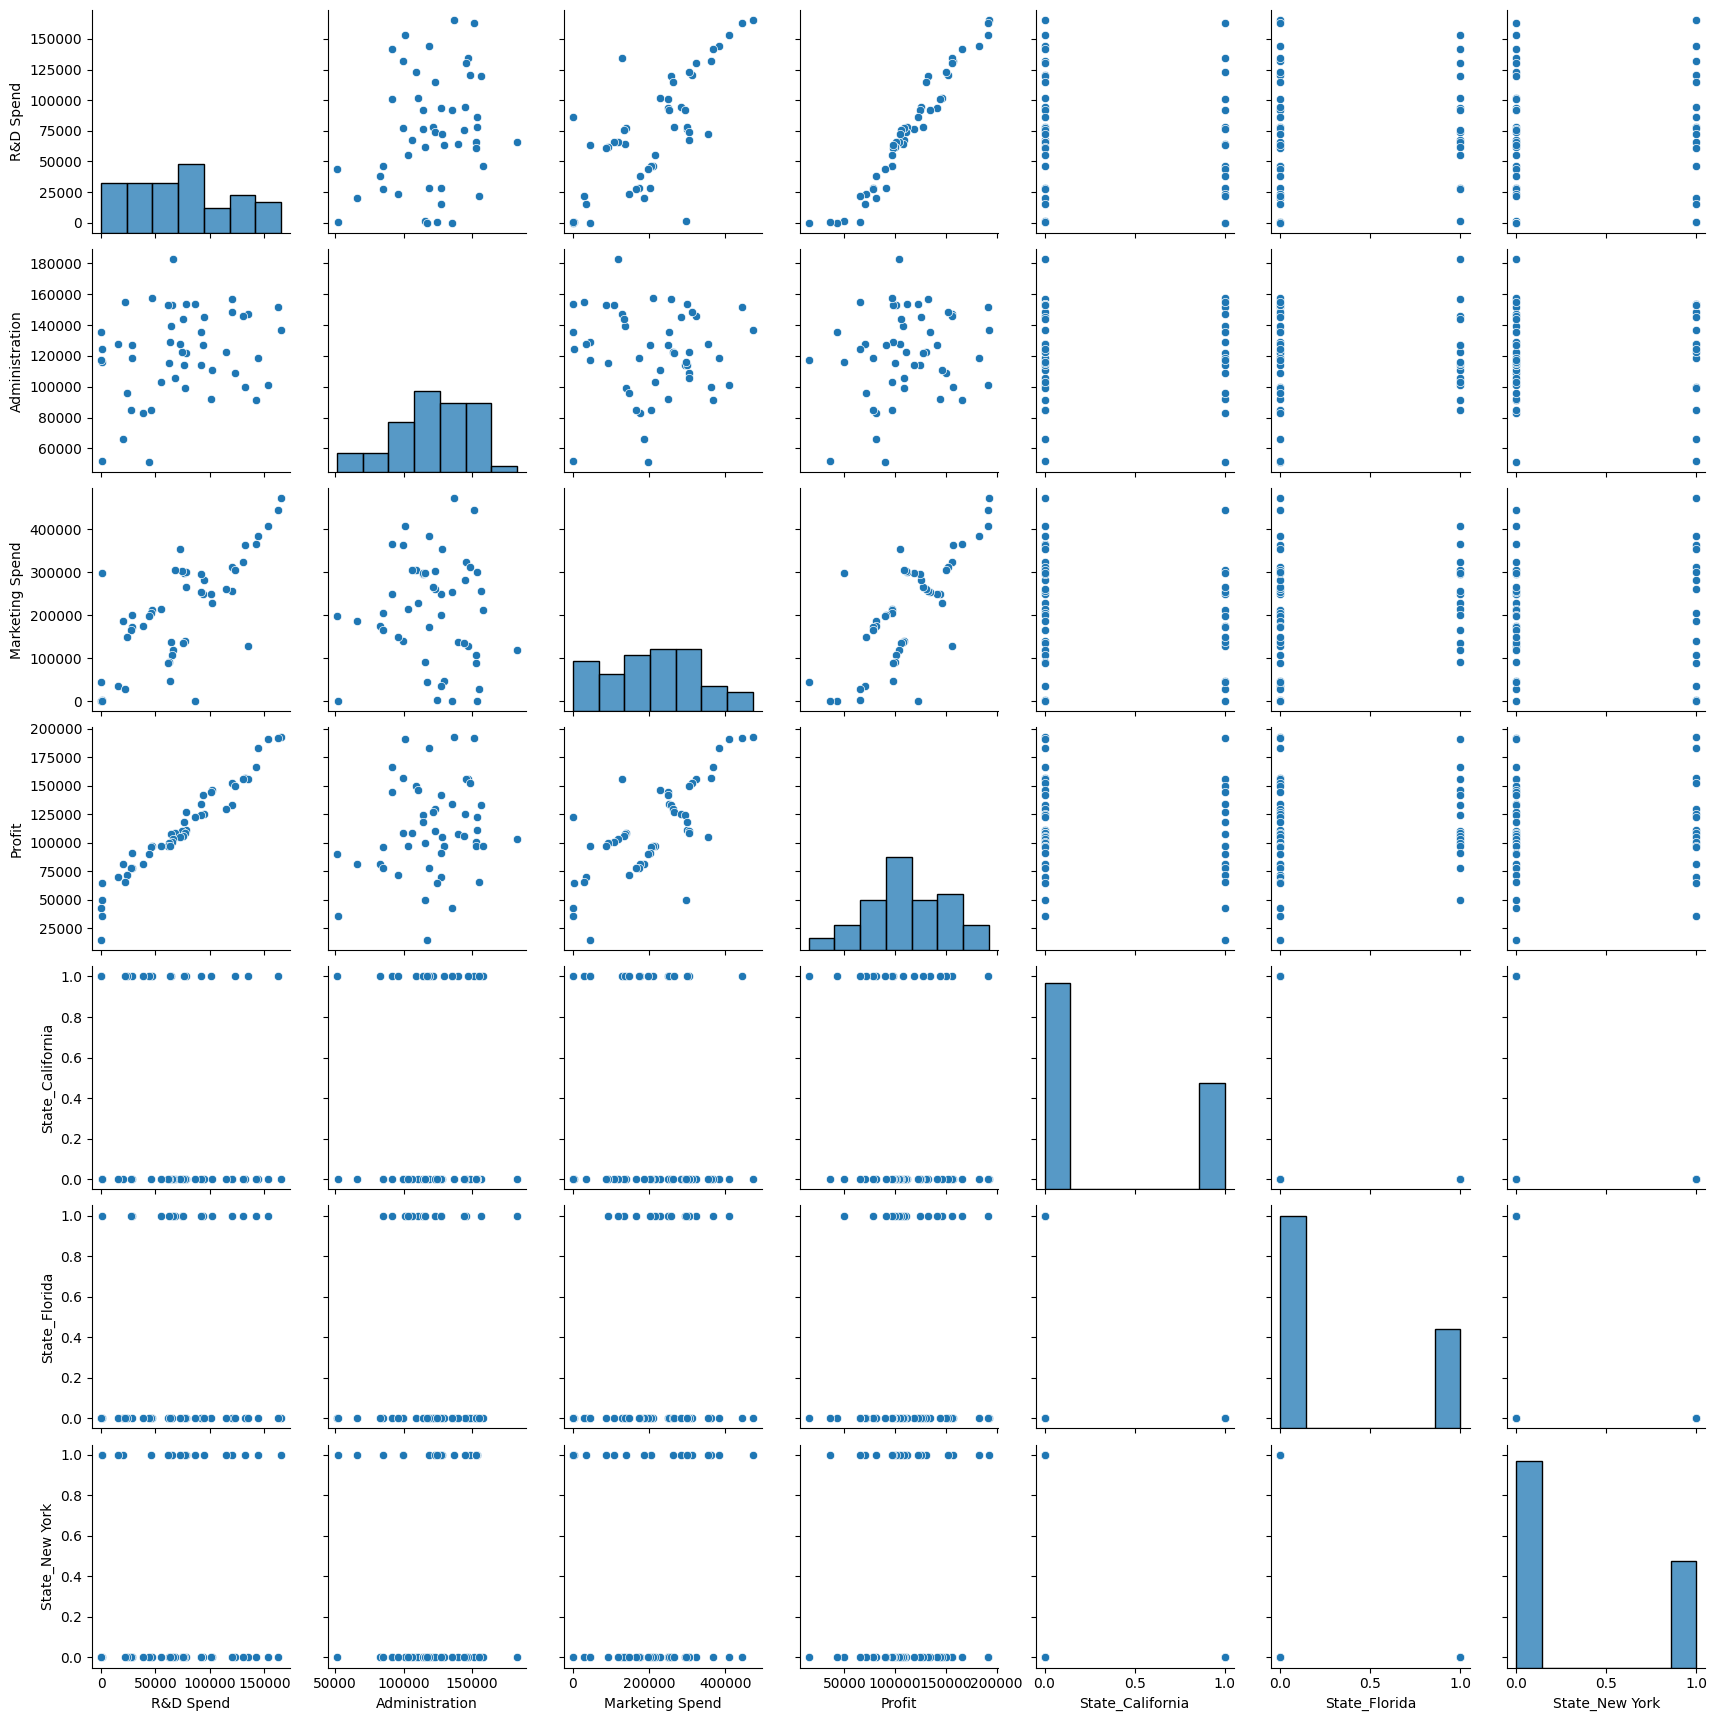

In [8]:
# relation ship bet 2 numerical variable
sns.pairplot(df) #for all data

<Axes: xlabel='R&D Spend', ylabel='Profit'>

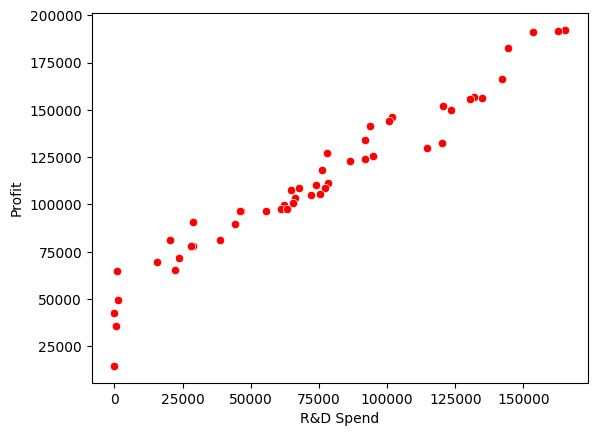

In [9]:
#scater plot for 2 fetchar
sns.scatterplot(x='R&D Spend', y='Profit', data=df , color = 'red')

In [10]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [11]:
df.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,False,False,True
1,162597.70,151377.59,443898.53,191792.06,True,False,False
2,153441.51,101145.55,407934.54,191050.39,False,True,False
3,144372.41,118671.85,383199.62,182901.99,False,False,True
4,142107.34,91391.77,366168.42,166187.94,False,True,False


In [12]:
#لو عايز اشوف القيم اللي في state

df['State_New York'].unique()

array([ True, False])

#encoding (from text to numeric)


In [13]:
#df_s = pd.get_dummies(df, columns=['State'])
#df_s=pd.get_dummies(df['State'] , drop_first=True )

In [14]:
df = pd.concat([df, pd.get_dummies(df['State_Florida'], drop_first=True)], axis=1)

In [15]:
df.drop(['State_New York'], axis=1, inplace=True)

In [16]:
df.drop(['State_California'], axis=1, inplace=True)

In [17]:
df.drop(['State_Florida'], axis=1, inplace=True)

In [18]:
df.head()

,R&D Spend,Administration,Marketing Spend,Profit,True
0,165349.20,136897.80,471784.10,192261.83,False
1,162597.70,151377.59,443898.53,191792.06,False
2,153441.51,101145.55,407934.54,191050.39,True
3,144372.41,118671.85,383199.62,182901.99,False
4,142107.34,91391.77,366168.42,166187.94,True


<Axes: >

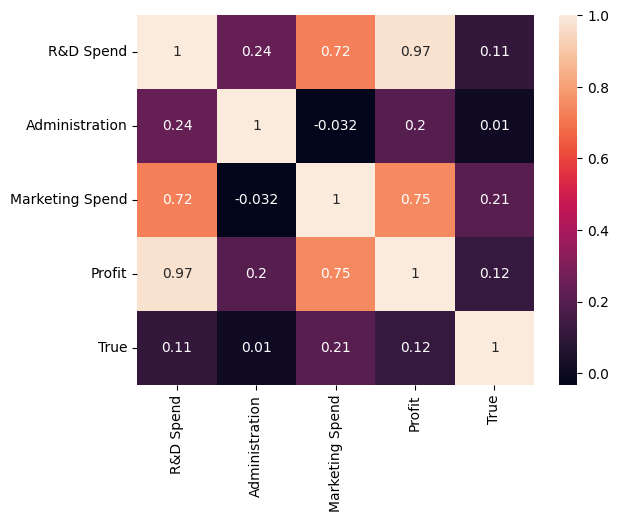

In [19]:
sns.heatmap(df.corr(), annot=True)


#SPLIT DATA

In [20]:
x = df.drop('Profit', axis=1) #كده كل العانصر عدا x
y = df['Profit']

In [21]:
x.head()

,R&D Spend,Administration,Marketing Spend,True
0,165349.20,136897.80,471784.10,False
1,162597.70,151377.59,443898.53,False
2,153441.51,101145.55,407934.54,True
3,144372.41,118671.85,383199.62,False
4,142107.34,91391.77,366168.42,True


In [22]:
y.head()

,Profit
0,192261.83
1,191792.06
2,191050.39
3,182901.99
4,166187.94


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
x_train , x_test, y_train, y_test = train_test_split(x, y,
                                                      test_size=0.2,
                                                      random_state=42)

#BULD MODEL

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
lm = LinearRegression()

In [28]:
x_train.columns = x_train.columns.astype(str)
x_test.columns = x_test.columns.astype(str) # Apply to x_test as well to avoid issues later

model = lm.fit(x_train, y_train) #علشا يتدرب

In [30]:
y_pred = model.predict(x_test)# علشان يطلع y_predict
#بعد كده عايز اقارنهم ببعض y_predict , x test
y_pred

array([126366.62112467,  84611.49884195,  99676.666304  ,  46352.84367716,
       128747.41218211,  50907.49149725, 109740.86073505, 100646.43527452,
        97602.02870814, 113093.157127  ])

#EVALUATION

In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [32]:
MSE = mean_squared_error(y_test, y_pred)
MSE

82010370.81024233

In [33]:
RMSE = np.sqrt(MSE)
RMSE

np.float64(9055.957752233737)

In [34]:
MAE = mean_absolute_error(y_test, y_pred)
MAE

6961.486845714203

In [35]:
model.score(x_train , y_train)

0.9537019951144616